In [1]:
%load_ext autoreload
%autoreload 2

In [41]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from model_sampler import DDIMSampler
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED

In [3]:
dataset = build_dataset('test')

In [18]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)

# Training

In [5]:
train_1000 = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
train_500 = ModelResults('113-t-500', 'ddpm-500', 199, 'test', dataset)
train_100 = ModelResults('114-t-100', 'ddpm-100', 199, 'test', dataset)
train_50 = ModelResults('115-t-50', 'ddpm-50', 199, 'test', dataset)
train_10 = ModelResults('116-t-10', 'ddpm-10', 199, 'test', dataset)
train_5 = ModelResults('117-t-5', 'ddpm-5', 199, 'test', dataset)
train_1 = ModelResults('118-t-1', 'ddpm-1', 199, 'test', dataset)

In [19]:
train_t_comparison = ModelComparison(
  [train_1000, train_500, train_100, train_50, train_10, train_5, train_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DDPM'] * 7 + ['U-Net']
)

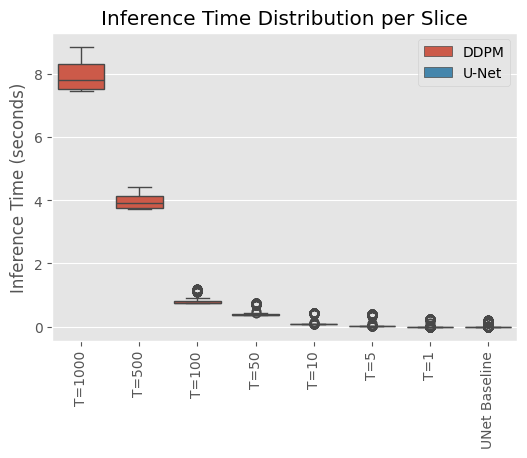

In [29]:
ax = train_t_comparison.plot_inference_times('slice', unit='seconds')
# ax.set_yscale('log')

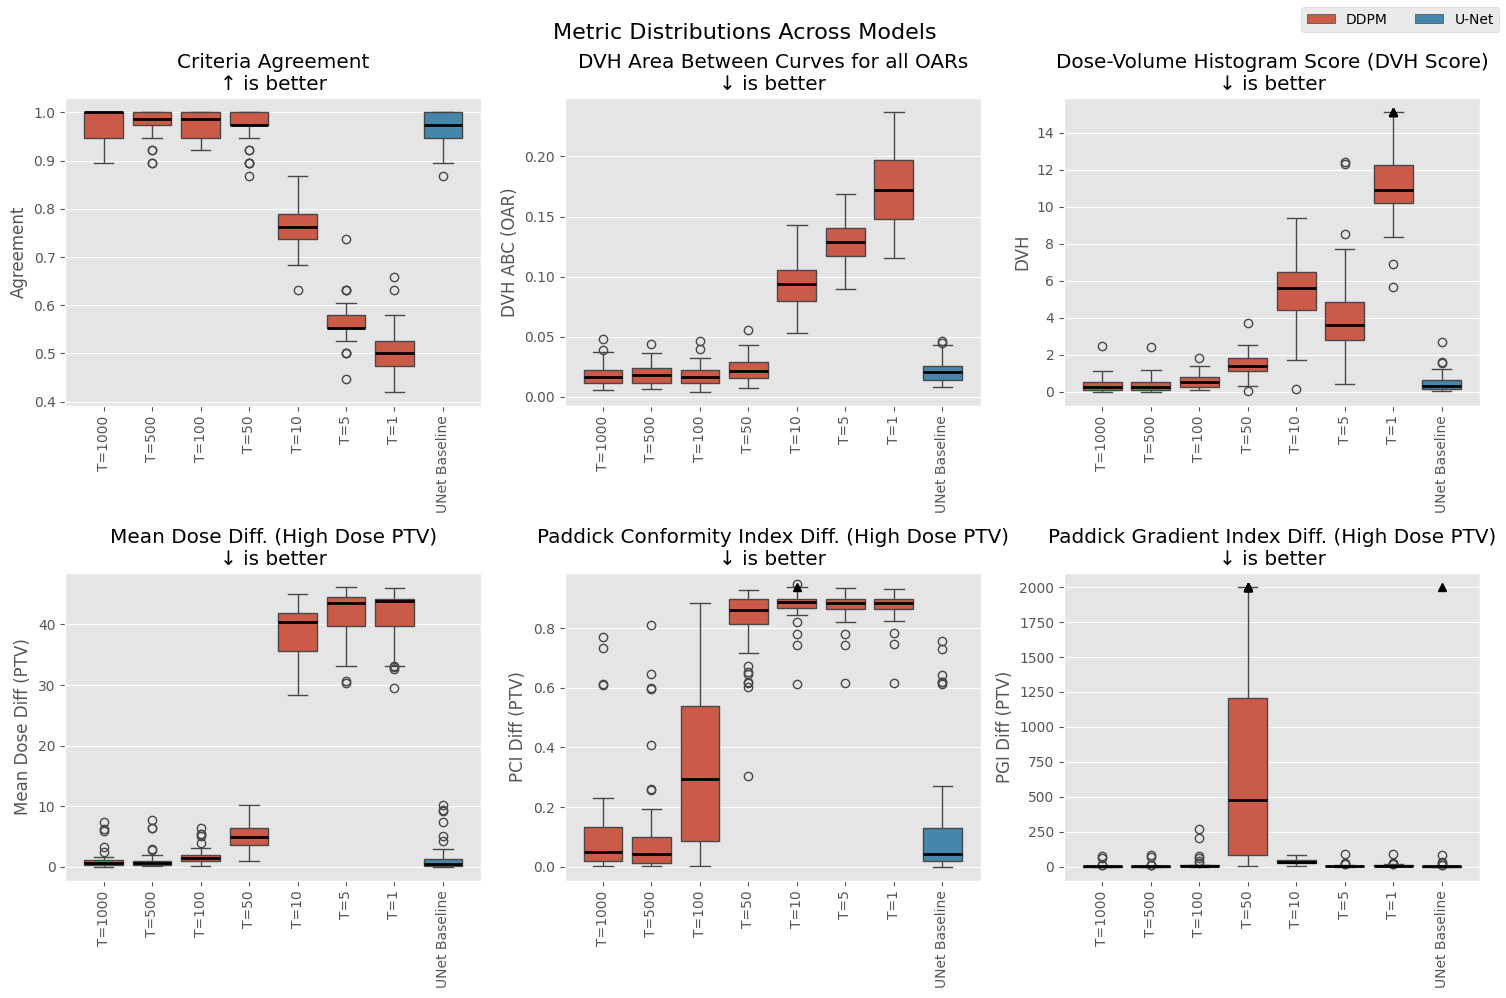

In [22]:
_ = train_t_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

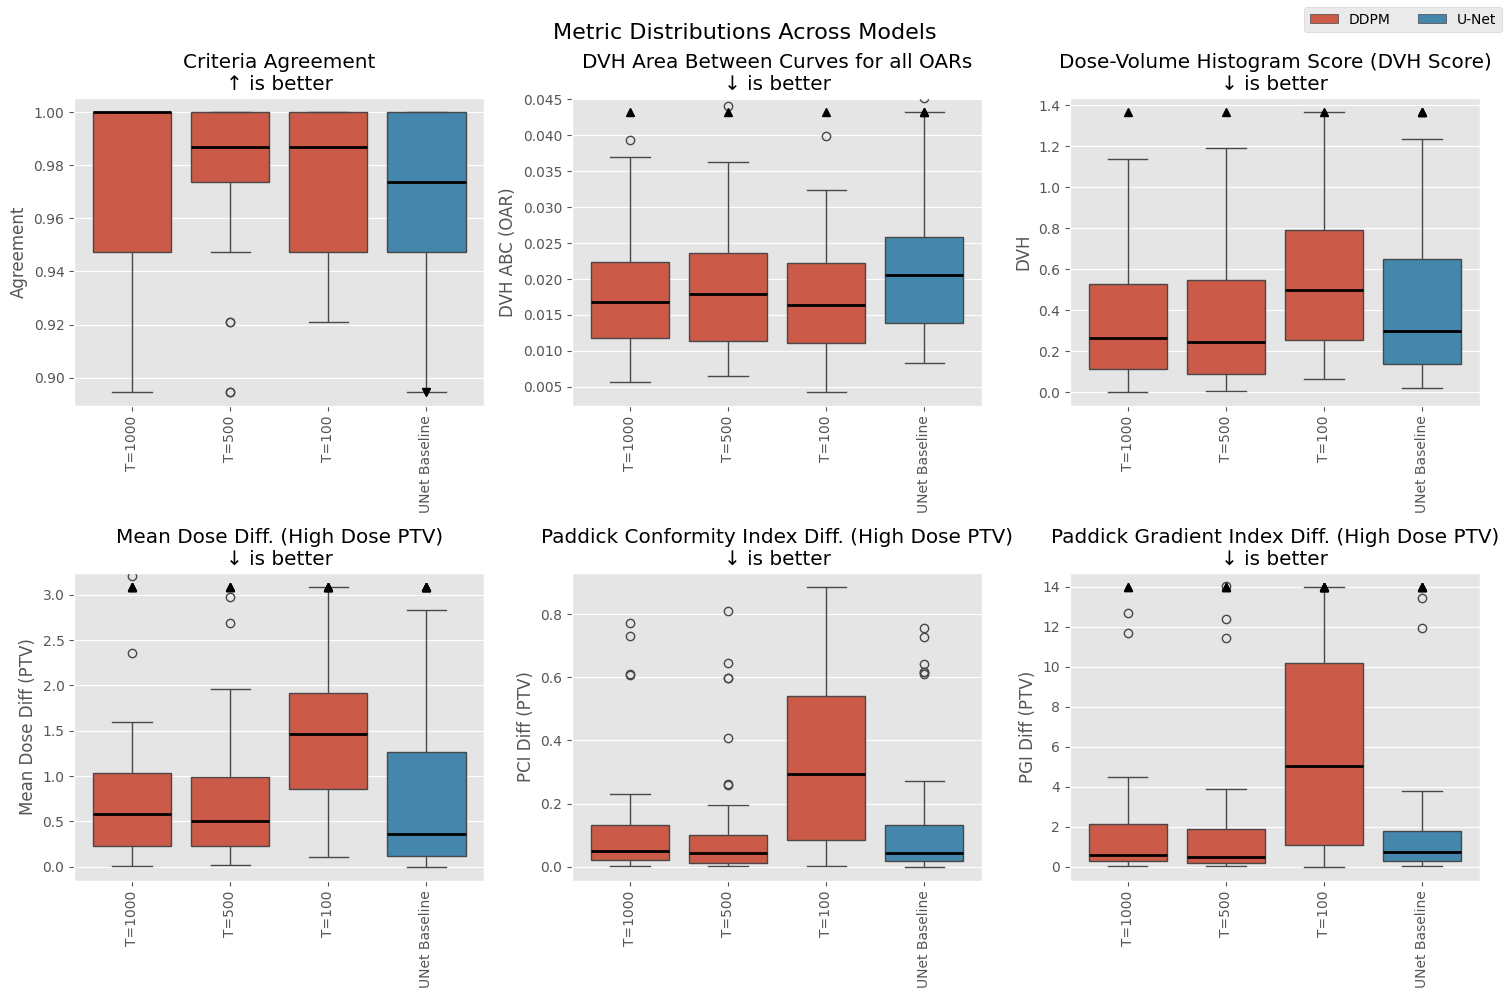

In [25]:
filtered_comparison = train_t_comparison - train_1 - train_5 - train_10 - train_50
_ = filtered_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

# DDPM Sampling

In [26]:
ddpm_1000 = train_1000
ddpm_500 = ModelResults('112-beamdiff-bf16', 'ddpm-500', 199, 'test', dataset)
ddpm_100 = ModelResults('112-beamdiff-bf16', 'ddpm-100', 199, 'test', dataset)
ddpm_50 = ModelResults('112-beamdiff-bf16', 'ddpm-50', 199, 'test', dataset)
ddpm_10 = ModelResults('112-beamdiff-bf16', 'ddpm-10', 199, 'test', dataset)
ddpm_5 = ModelResults('112-beamdiff-bf16', 'ddpm-5', 199, 'test', dataset)
ddpm_1 = ModelResults('112-beamdiff-bf16', 'ddpm-1', 199, 'test', dataset)

In [27]:
ddpm_comparison = ModelComparison(
  [ddpm_1000, ddpm_500, ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DDPM'] * 7 + ['U-Net']
)

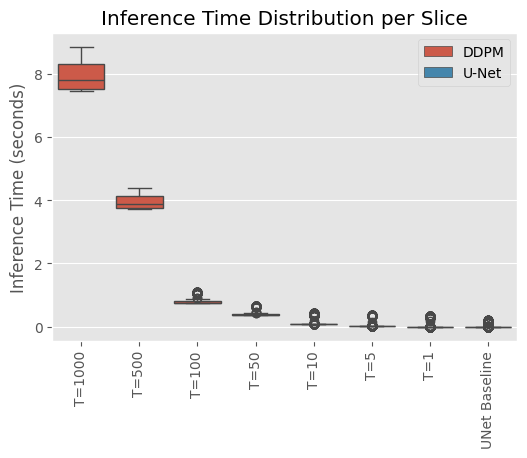

In [28]:
_ = ddpm_comparison.plot_inference_times('slice', unit='seconds')

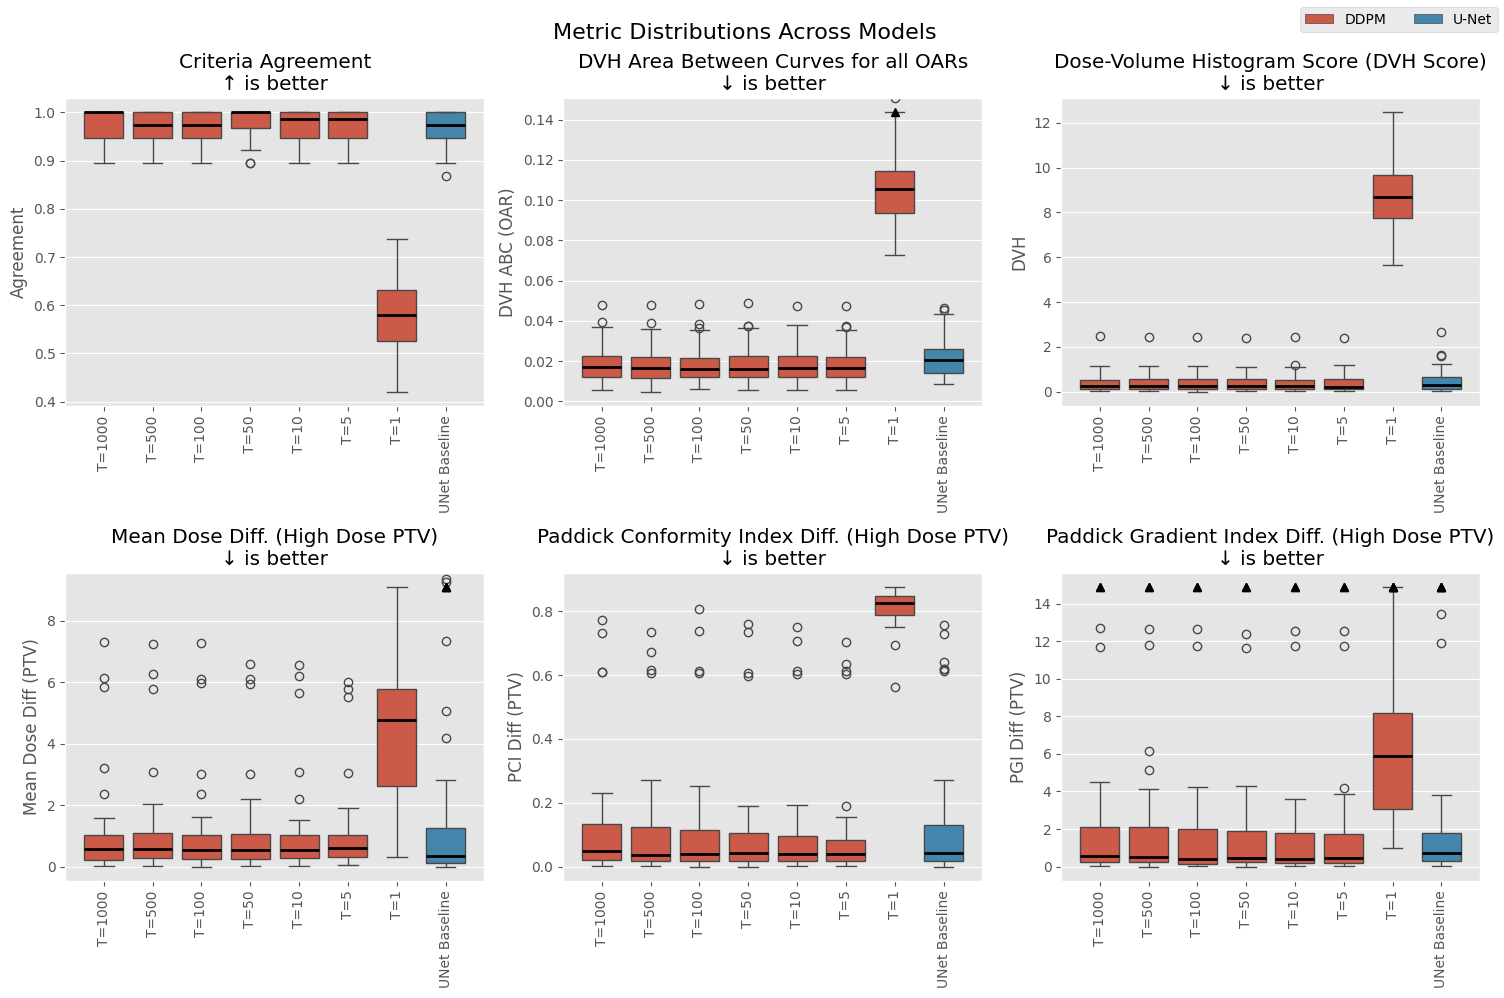

In [30]:
_ = ddpm_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

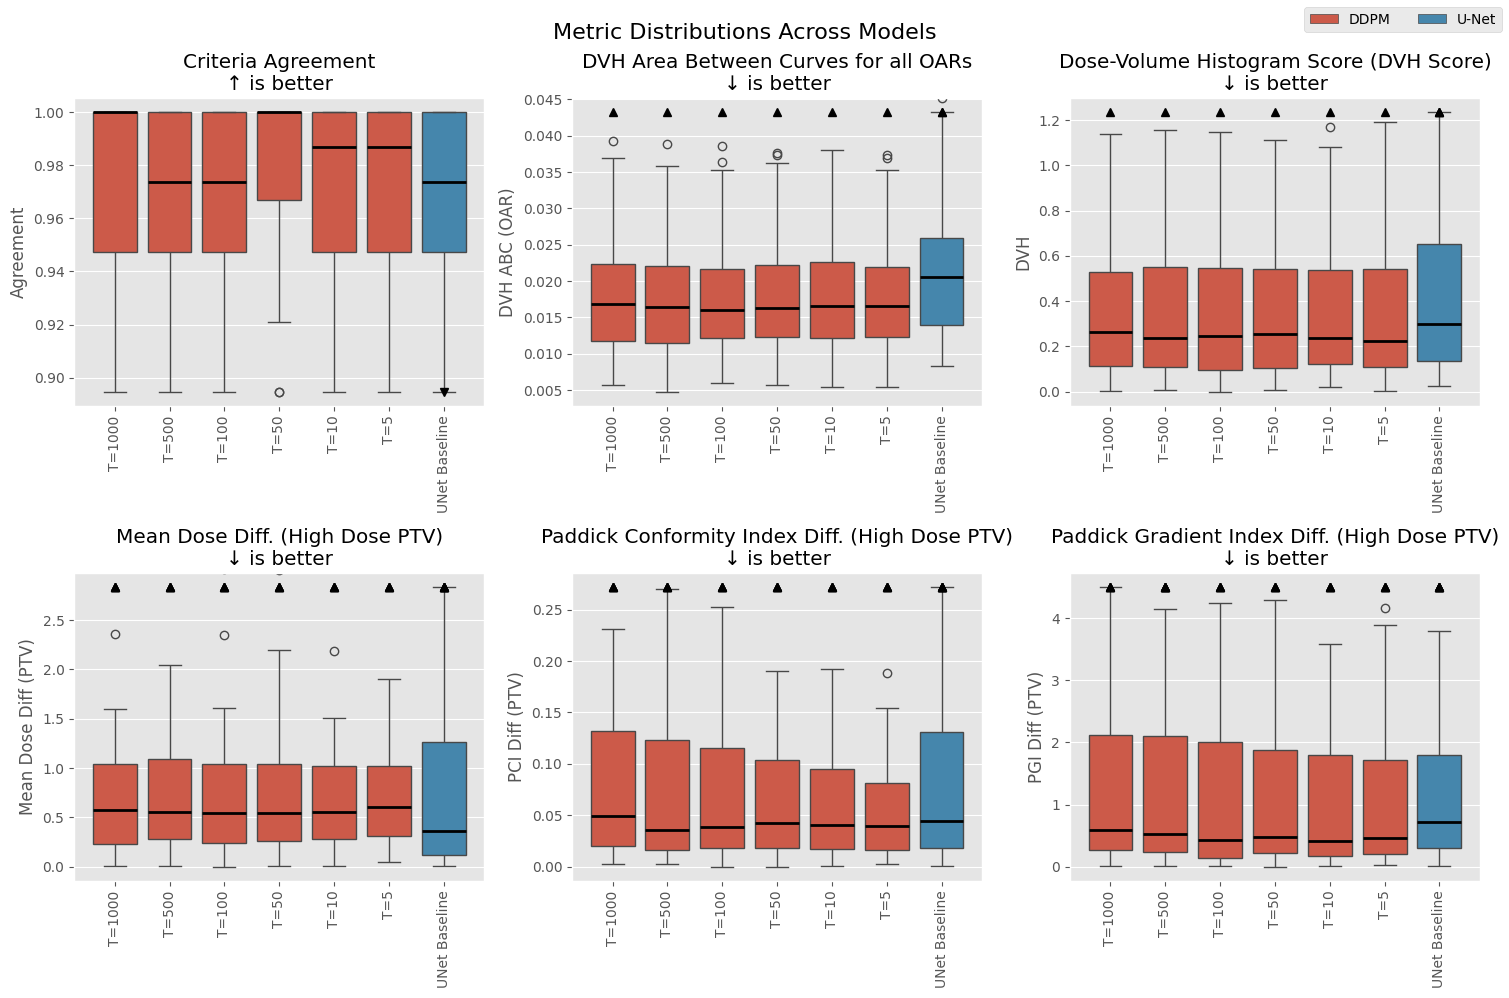

In [31]:
filtered_comparison = ddpm_comparison - ddpm_1
_ = filtered_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

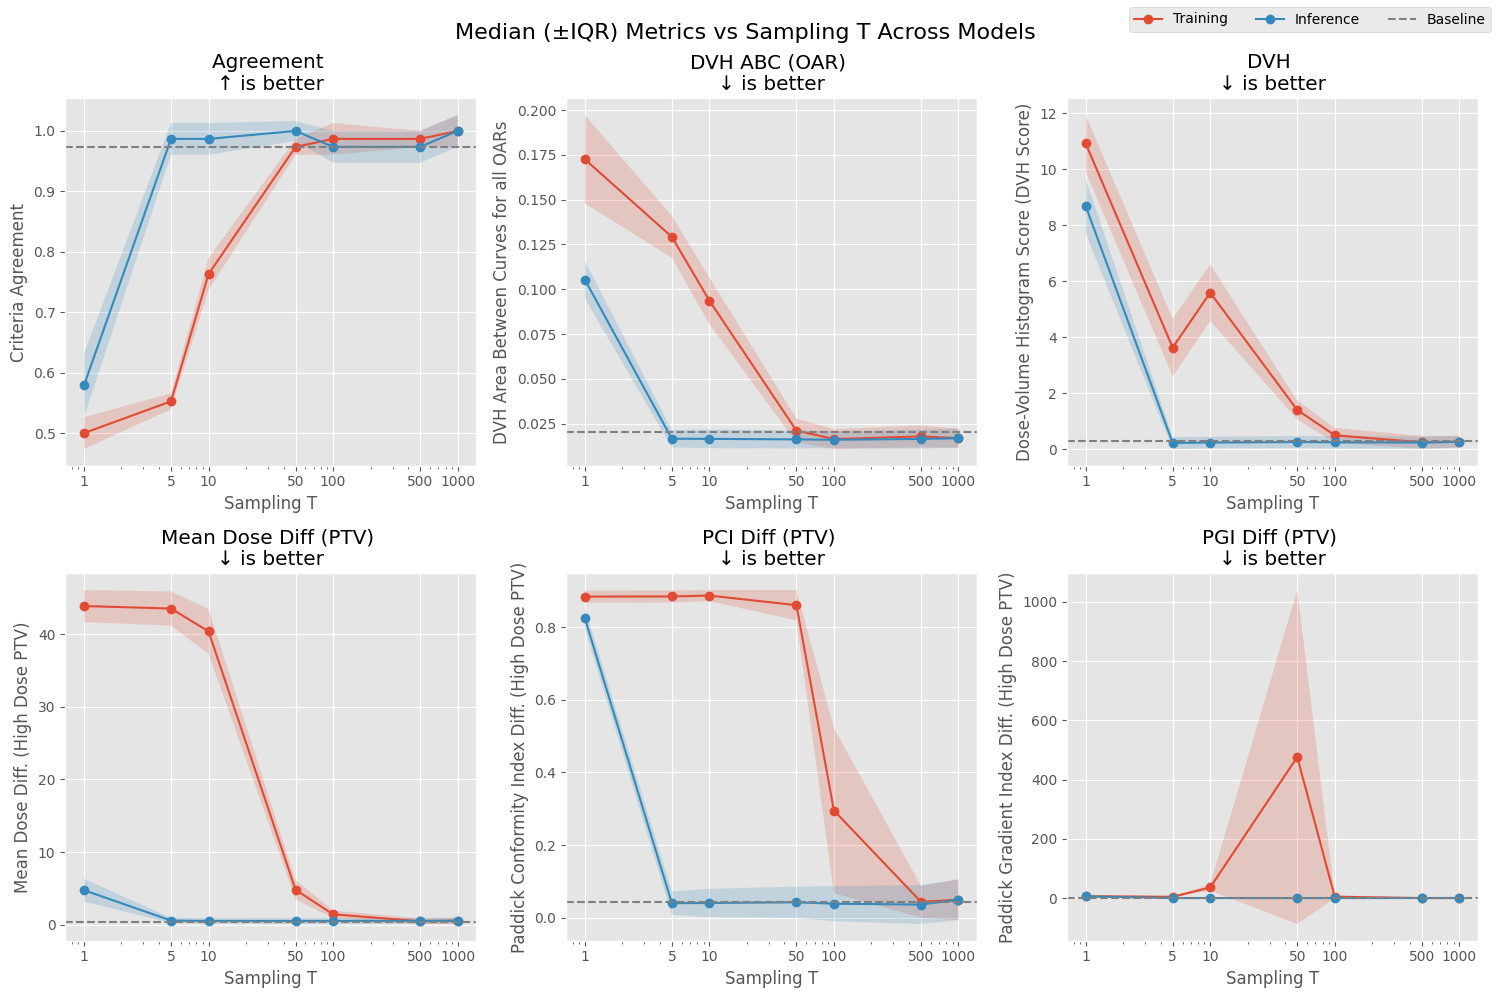

In [85]:
train_ddpm_comparison = ModelComparison(
  [train_1000, train_500, train_100, train_50, train_10, train_5, train_1] +
  [ddpm_1000, ddpm_500, ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_1],
  ['Training T=1000', 'Training T=500', 'Training T=100', 'Training T=50', 'Training T=10', 'Training T=5', 'Training T=1'] +
  ['Inference T=1000', 'Inference T=500', 'Inference T=100', 'Inference T=50', 'Inference T=10', 'Inference T=5', 'Inference T=1'],
  ['DDPM-Train'] * 7 + ['DDPM-Infer'] * 7
)
_ = train_ddpm_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)


# DDIM-Sampling

In [32]:
ddim_1000 = ModelResults('112-beamdiff-bf16', 'ddim-1000', 199, 'test', dataset)
ddim_500 = ModelResults('112-beamdiff-bf16', 'ddim-500', 199, 'test', dataset)
ddim_100 = ModelResults('112-beamdiff-bf16', 'ddim-100', 199, 'test', dataset)
ddim_50 = ModelResults('112-beamdiff-bf16', 'ddim-50', 199, 'test', dataset)
ddim_10 = ModelResults('112-beamdiff-bf16', 'ddim-10', 199, 'test', dataset)
ddim_5 = ModelResults('112-beamdiff-bf16', 'ddim-5', 199, 'test', dataset)
ddim_1 = ModelResults('112-beamdiff-bf16', 'ddim-1', 199, 'test', dataset)

In [33]:
ddim_comparison = ModelComparison(
  [ddim_1000, ddim_500, ddim_100, ddim_50, ddim_10, ddim_5, ddim_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DDIM'] * 7 + ['U-Net']
)

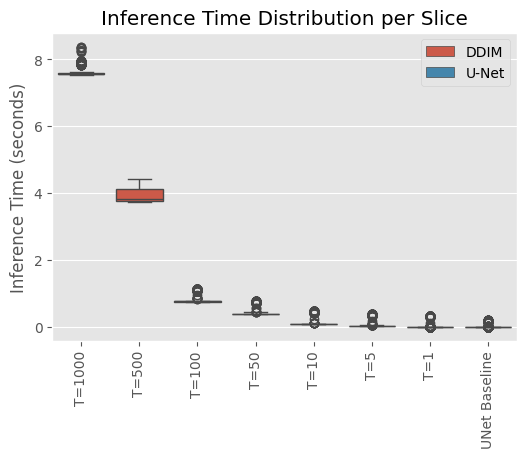

In [34]:
_ = ddim_comparison.plot_inference_times('slice', unit='seconds')

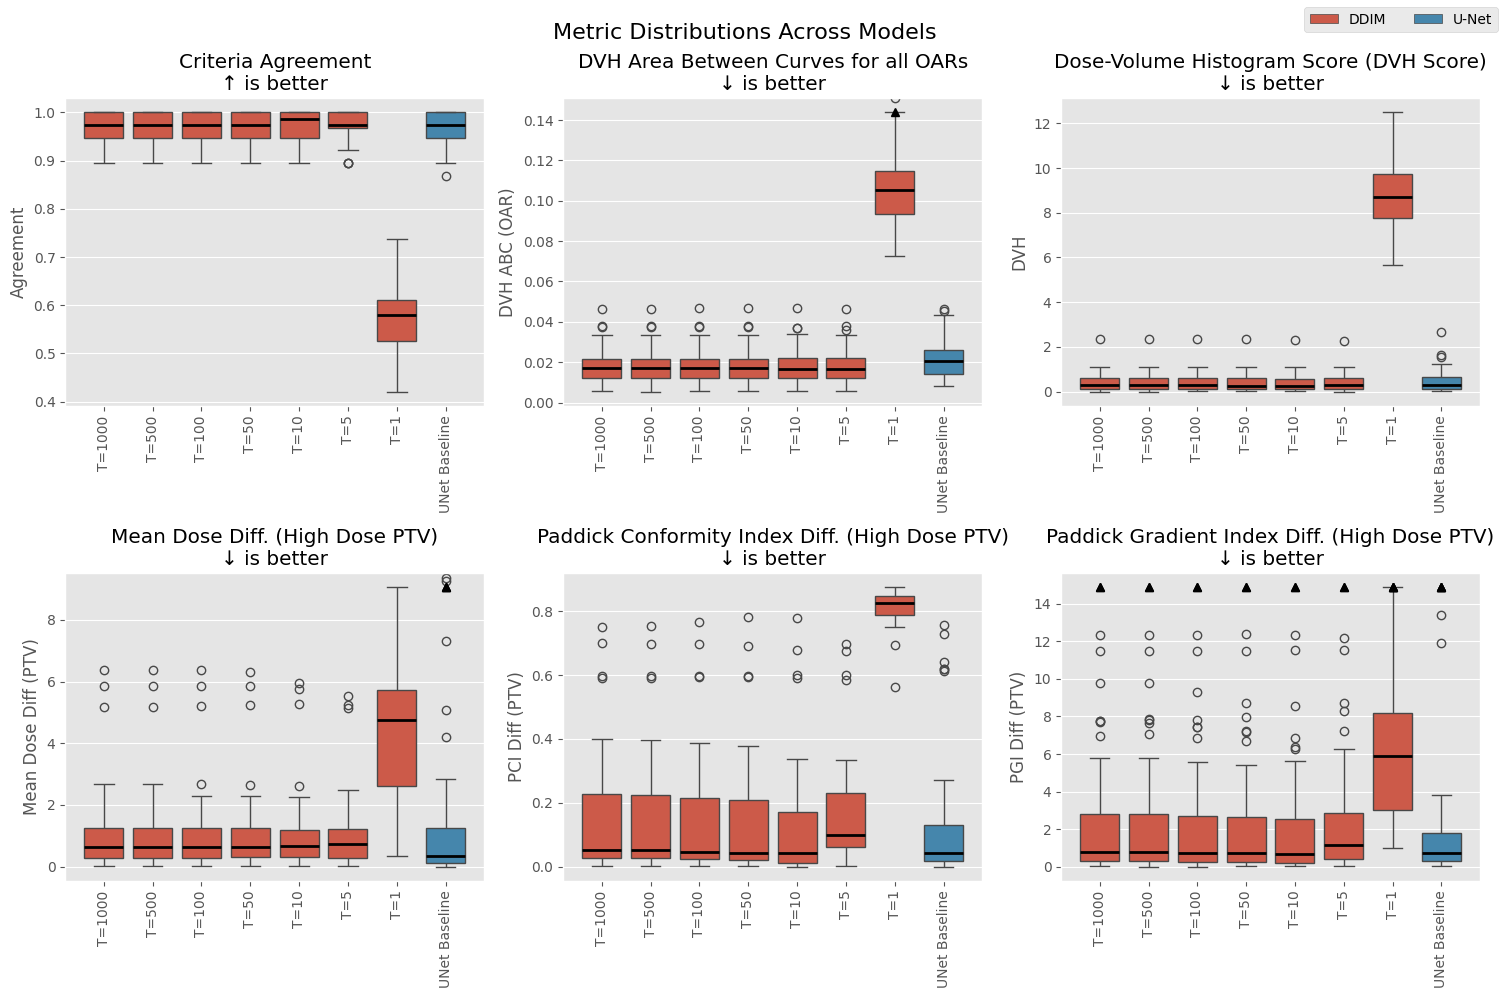

In [35]:
_ = ddim_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

# DDIM with Cosine Scheduling

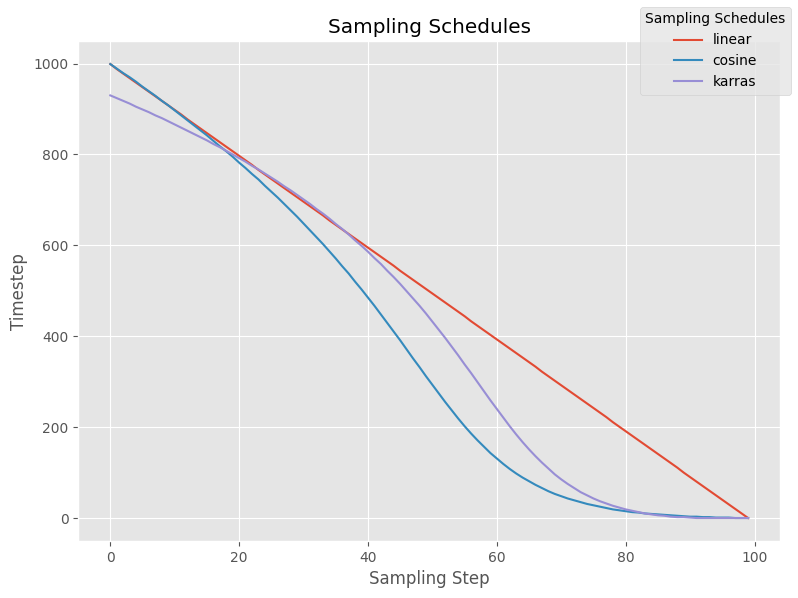

In [42]:
linear_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'linear')
cosine_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'cosine')
karras_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'karras')

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(linear_sampler.sampling_indices, label='linear')
ax.plot(cosine_sampler.sampling_indices, label='cosine')
ax.plot(karras_sampler.sampling_indices, label='karras')
fig.legend(title='Sampling Schedules', loc='upper right')
ax.set_title('Sampling Schedules')
ax.set_xlabel('Sampling Step')
ax.set_ylabel('Timestep')
fig.tight_layout()


In [38]:
ddim_cosine_1000 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-1000', 199, 'test', dataset)
ddim_cosine_500 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-500', 199, 'test', dataset)
ddim_cosine_100 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-100', 199, 'test', dataset)
ddim_cosine_50 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-50', 199, 'test', dataset)
ddim_cosine_10 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-10', 199, 'test', dataset)
ddim_cosine_5 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-5', 199, 'test', dataset)
ddim_cosine_1 = ModelResults('112-beamdiff-bf16', 'ddim-cosine-1', 199, 'test', dataset)

In [39]:
ddim_cosine_comparison = ModelComparison(
  [ddim_cosine_1000, ddim_cosine_500, ddim_cosine_100, ddim_cosine_50, ddim_cosine_10, ddim_cosine_5, ddim_cosine_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DDIM-Cosine'] * 7 + ['U-Net']
)

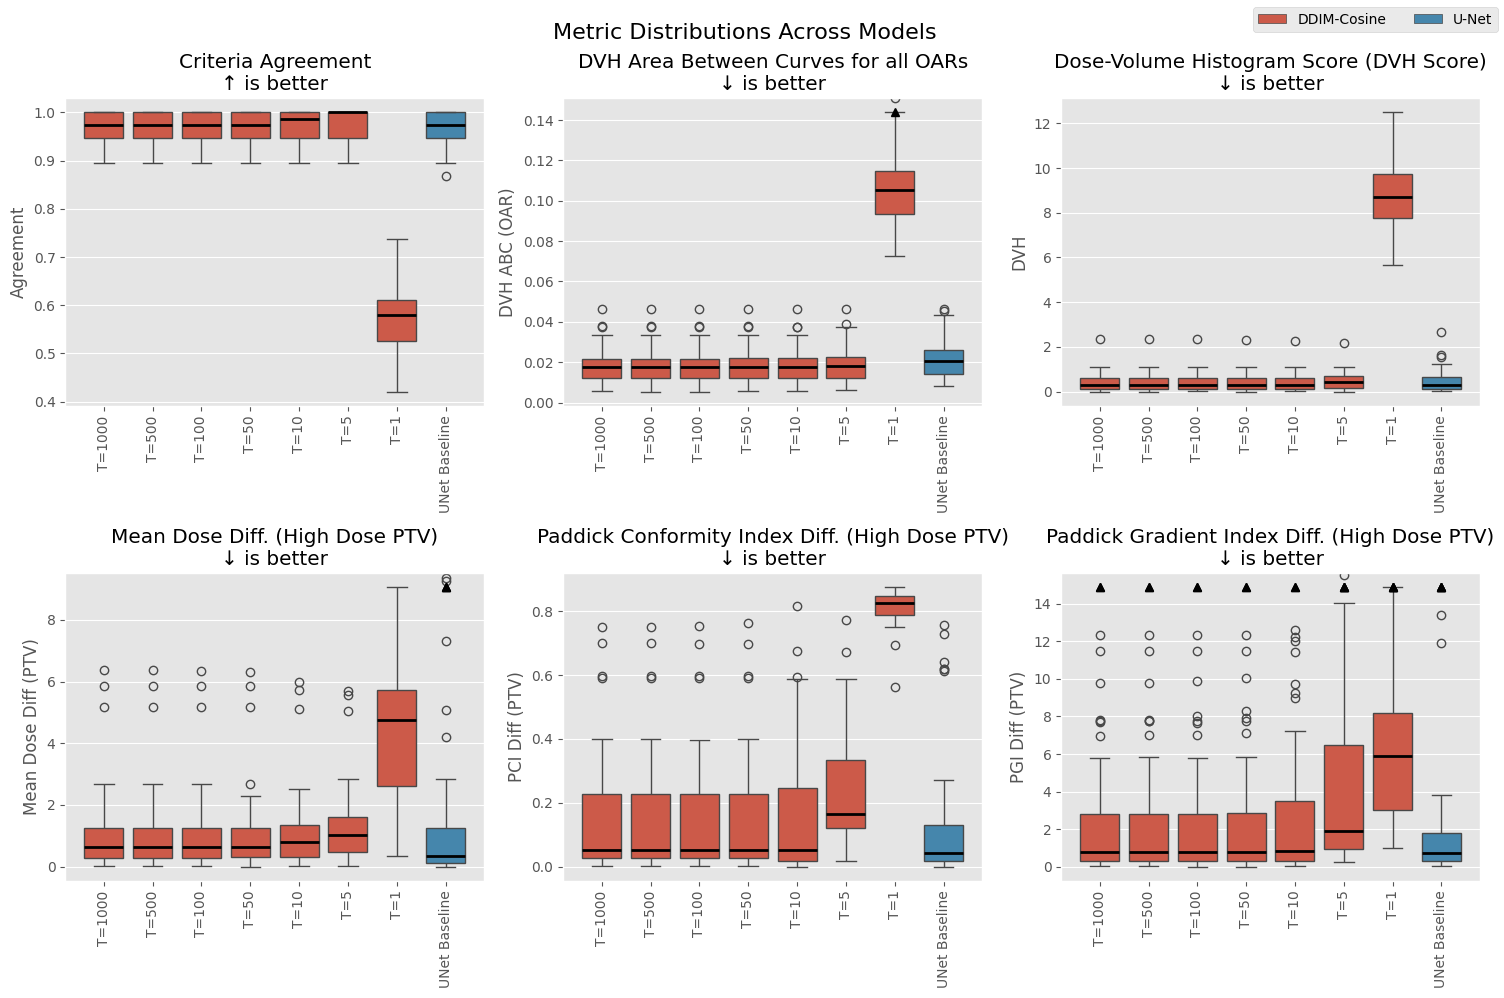

In [40]:
_ = ddim_cosine_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

# DDIM with Karras Scheduling

In [43]:
ddim_karras_1000 = ModelResults('112-beamdiff-bf16', 'ddim-karras-1000', 199, 'test', dataset)
ddim_karras_500 = ModelResults('112-beamdiff-bf16', 'ddim-karras-500', 199, 'test', dataset)
ddim_karras_100 = ModelResults('112-beamdiff-bf16', 'ddim-karras-100', 199, 'test', dataset)
ddim_karras_50 = ModelResults('112-beamdiff-bf16', 'ddim-karras-50', 199, 'test', dataset)
ddim_karras_10 = ModelResults('112-beamdiff-bf16', 'ddim-karras-10', 199, 'test', dataset)
ddim_karras_5 = ModelResults('112-beamdiff-bf16', 'ddim-karras-5', 199, 'test', dataset)
ddim_karras_1 = ModelResults('112-beamdiff-bf16', 'ddim-karras-1', 199, 'test', dataset)

In [44]:
ddim_karras_comparison = ModelComparison(
  [ddim_karras_1000, ddim_karras_500, ddim_karras_100, ddim_karras_50, ddim_karras_10, ddim_karras_5, ddim_karras_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DDIM-Karras'] * 7 + ['U-Net']
)

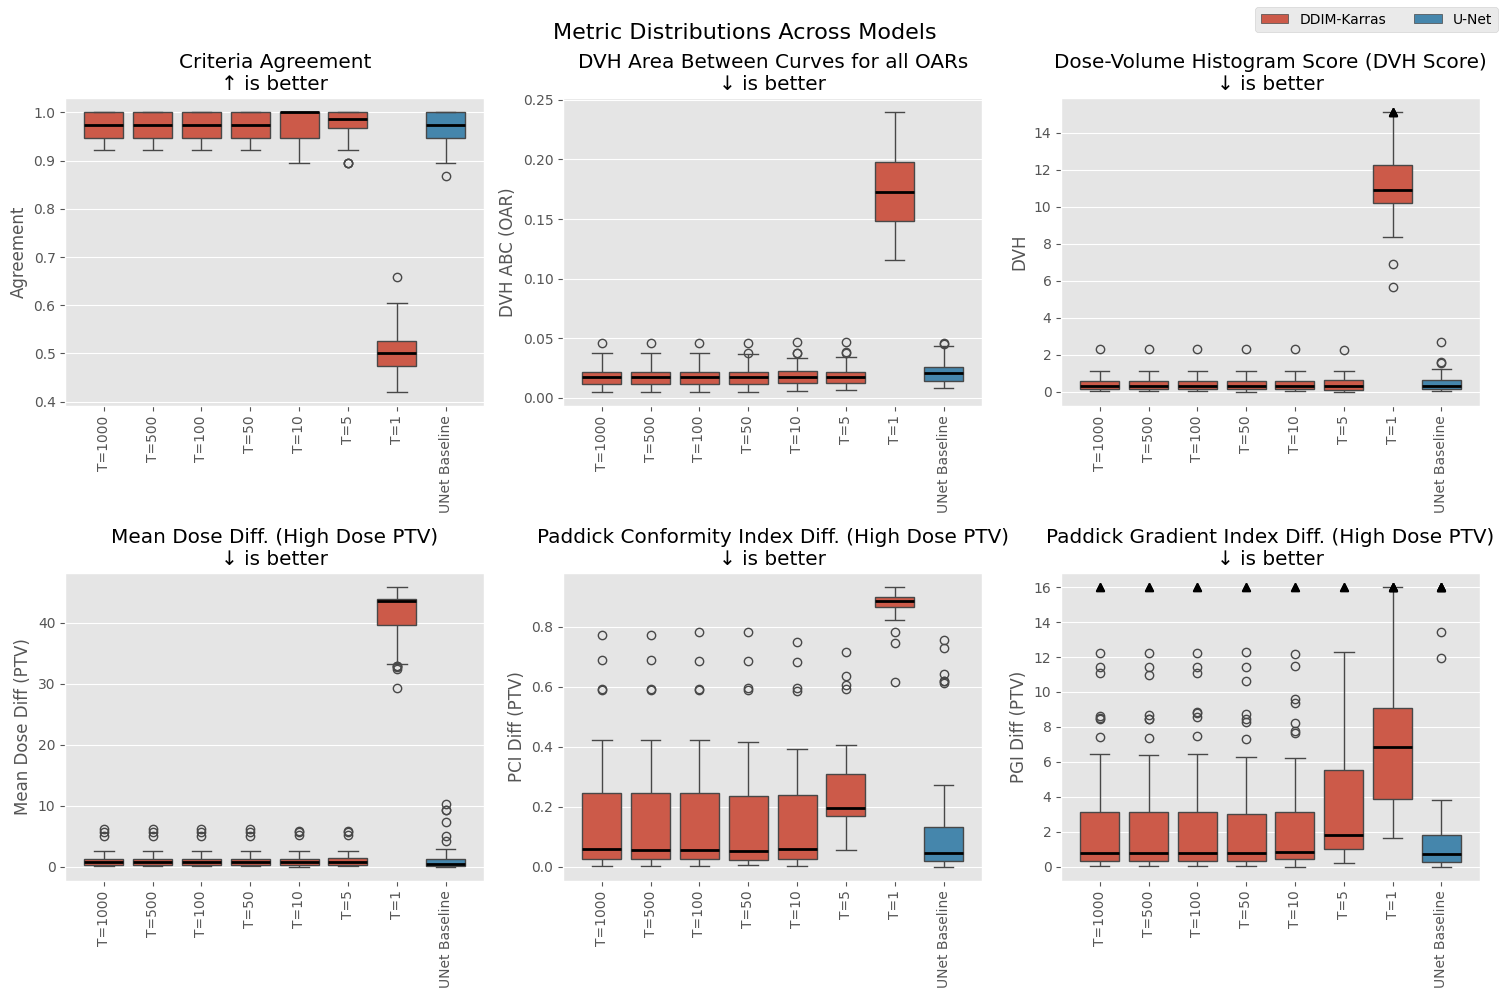

In [45]:
_ = ddim_karras_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

# DDIM-Comparison

In [ ]:
ddim_schedule_comparison = ModelComparison(
  [ddim_1000, ddim_500, ddim_100, ddim_50, ddim_10, ddim_5, ddim_1] +
  [ddim_cosine_1000, ddim_cosine_500, ddim_cosine_100, ddim_cosine_50, ddim_cosine_10, ddim_cosine_5, ddim_cosine_1] +
  [ddim_karras_1000, ddim_karras_500, ddim_karras_100, ddim_karras_50, ddim_karras_10, ddim_karras_5, ddim_karras_1],
  ['Linear T=10000', 'Linear T=500', 'Linear T=100', 'Linear T=50', 'Linear T=10', 'Linear T=5', 'Linear T=1'] +
  ['Cosine T=1000', 'Cosine T=500', 'Cosine T=100', 'Cosine T=50', 'Cosine T=10', 'Cosine T=5', 'Cosine T=1'] +
  ['Karras T=1000', 'Karras T=500', 'Karras T=100', 'Karras T=50', 'Karras T=10', 'Karras T=5', 'Karras T=1'],
  ['DDIM-Linear'] * 7 + ['DDIM-Cosine'] * 7 + ['DDIM-Karras'] *7
)

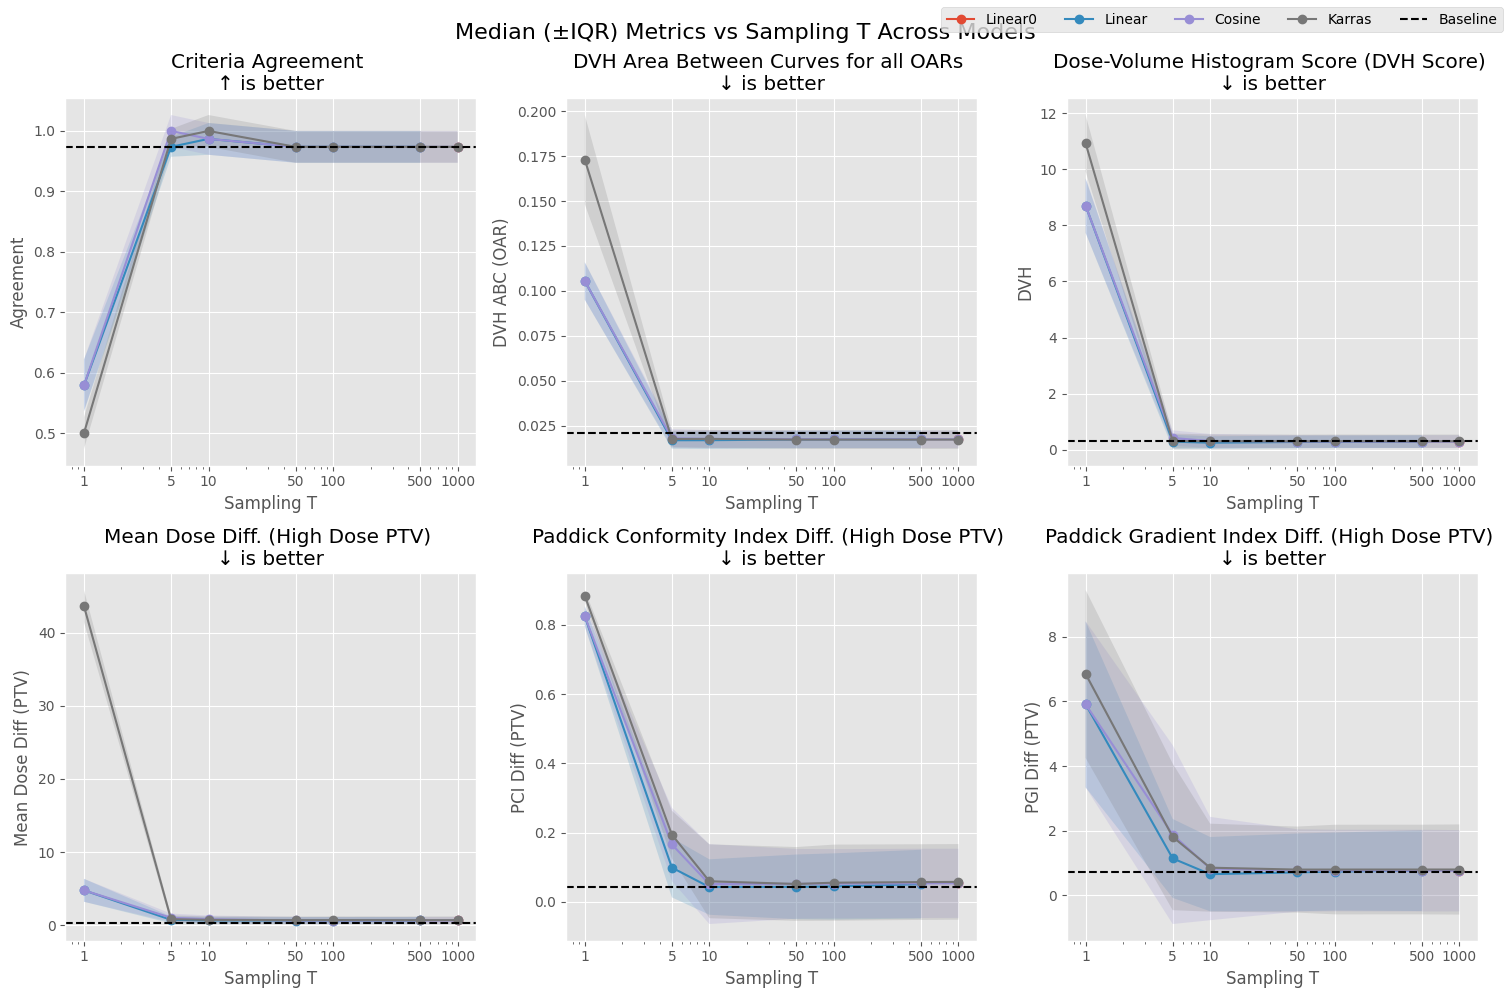

In [90]:
_ = ddim_schedule_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)

# DEIS Sampling

In [93]:
deis_1_1000 = ModelResults('112-beamdiff-bf16', 'deis-1-1000', 199, 'test', dataset)
deis_1_500 = ModelResults('112-beamdiff-bf16', 'deis-1-500', 199, 'test', dataset)
deis_1_100 = ModelResults('112-beamdiff-bf16', 'deis-1-100', 199, 'test', dataset)
deis_1_50 = ModelResults('112-beamdiff-bf16', 'deis-1-50', 199, 'test', dataset)
deis_1_10 = ModelResults('112-beamdiff-bf16', 'deis-1-10', 199, 'test', dataset)
deis_1_5 = ModelResults('112-beamdiff-bf16', 'deis-1-5', 199, 'test', dataset)
deis_1_1 = ModelResults('112-beamdiff-bf16', 'deis-1-1', 199, 'test', dataset)

In [94]:
deis_1_comparison = ModelComparison(
  [deis_1_1000, deis_1_500, deis_1_100, deis_1_50, deis_1_10, deis_1_5, deis_1_1, unet_baseline],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=1', 'UNet Baseline'],
  ['DEIS-1'] * 7 + ['UNet']
)

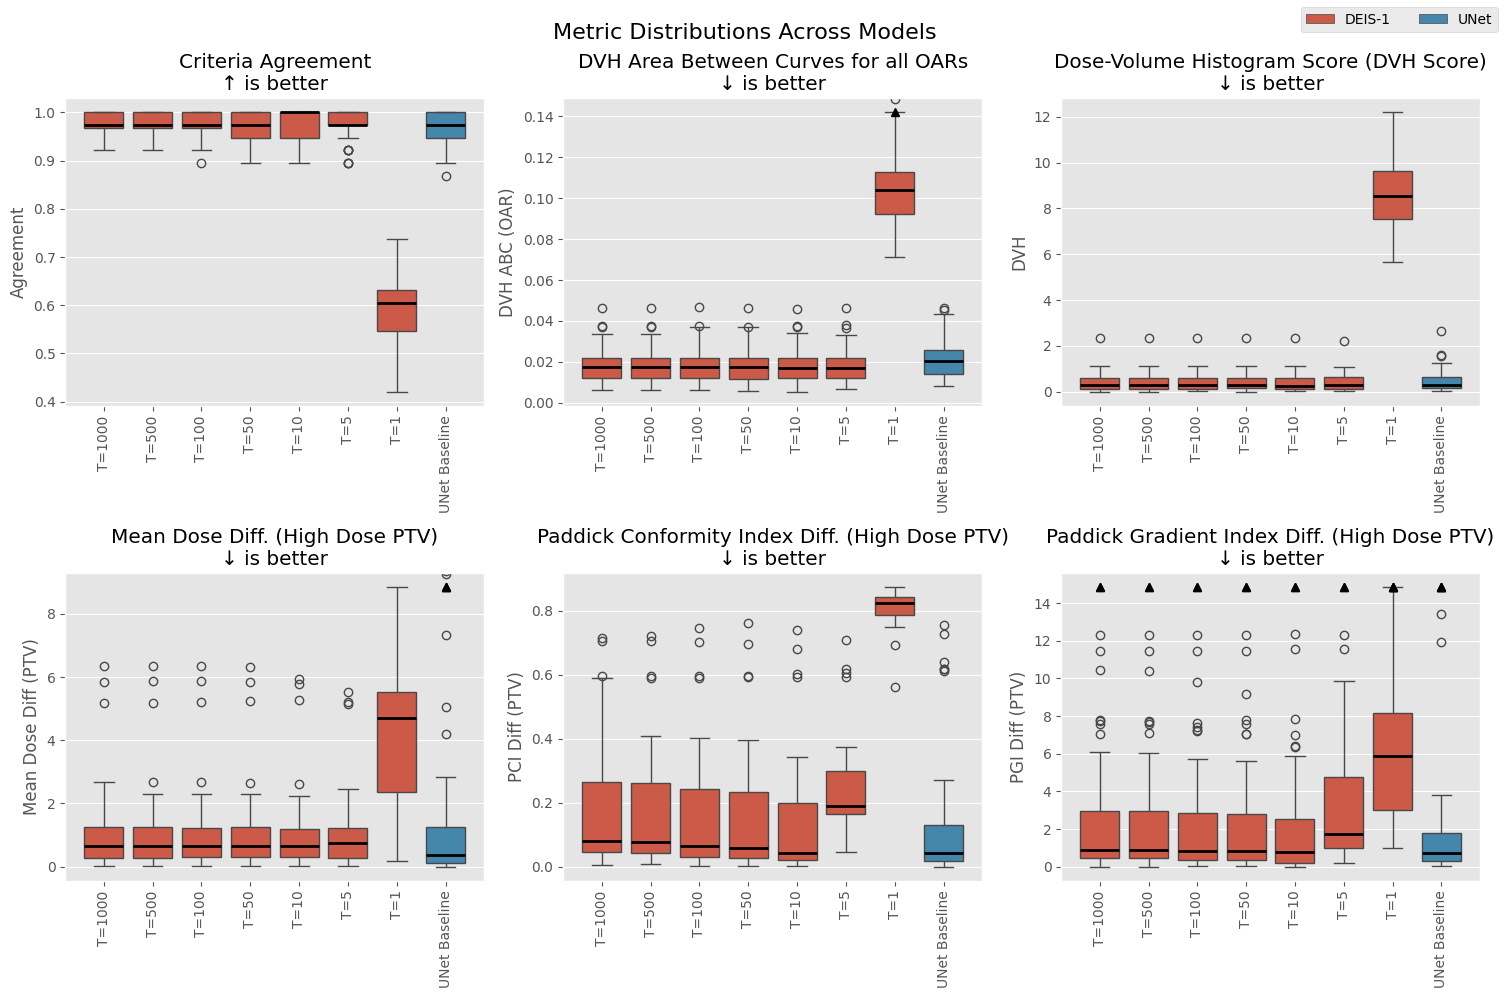

In [96]:
_ = deis_1_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

In [97]:
deis_2_1000 = ModelResults('112-beamdiff-bf16', 'deis-2-1000', 199, 'test', dataset)
deis_2_500 = ModelResults('112-beamdiff-bf16', 'deis-2-500', 199, 'test', dataset)
deis_2_100 = ModelResults('112-beamdiff-bf16', 'deis-2-100', 199, 'test', dataset)
deis_2_50 = ModelResults('112-beamdiff-bf16', 'deis-2-50', 199, 'test', dataset)
deis_2_10 = ModelResults('112-beamdiff-bf16', 'deis-2-10', 199, 'test', dataset)
deis_2_5 = ModelResults('112-beamdiff-bf16', 'deis-2-5', 199, 'test', dataset)
deis_2_1 = ModelResults('112-beamdiff-bf16', 'deis-2-1', 199, 'test', dataset)

In [98]:
deis_3_1000 = ModelResults('112-beamdiff-bf16', 'deis-3-1000', 199, 'test', dataset)
deis_3_500 = ModelResults('112-beamdiff-bf16', 'deis-3-500', 199, 'test', dataset)
deis_3_100 = ModelResults('112-beamdiff-bf16', 'deis-3-100', 199, 'test', dataset)
deis_3_50 = ModelResults('112-beamdiff-bf16', 'deis-3-50', 199, 'test', dataset)
deis_3_10 = ModelResults('112-beamdiff-bf16', 'deis-3-10', 199, 'test', dataset)
deis_3_5 = ModelResults('112-beamdiff-bf16', 'deis-3-5', 199, 'test', dataset)
deis_3_1 = ModelResults('112-beamdiff-bf16', 'deis-3-1', 199, 'test', dataset)

In [99]:
deis_comparison = ModelComparison(
  [deis_1_1000, deis_1_500, deis_1_100, deis_1_50, deis_1_10, deis_1_5, deis_1_1,
   deis_2_1000, deis_2_500, deis_2_100, deis_2_50, deis_2_10, deis_2_5, deis_2_1,
   deis_3_1000, deis_3_500, deis_3_100, deis_3_50, deis_3_10, deis_3_5, deis_3_1],
  ['DEIS-1 T=1000', 'DEIS-1 T=500', 'DEIS-1 T=100', 'DEIS-1 T=50', 'DEIS-1 T=10', 'DEIS-1 T=5', 'DEIS-1 T=1',
    'DEIS-2 T=1000', 'DEIS-2 T=500', 'DEIS-2 T=100', 'DEIS-2 T=50', 'DEIS-2 T=10', 'DEIS-2 T=5', 'DEIS-2 T=1',
    'DEIS-3 T=1000', 'DEIS-3 T=500', 'DEIS-3 T=100', 'DEIS-3 T=50', 'DEIS-3 T=10', 'DEIS-3 T=5', 'DEIS-3 T=1'],
    ['DEIS-1'] * 7 + ['DEIS-2'] * 7 + ['DEIS-3'] *7
)

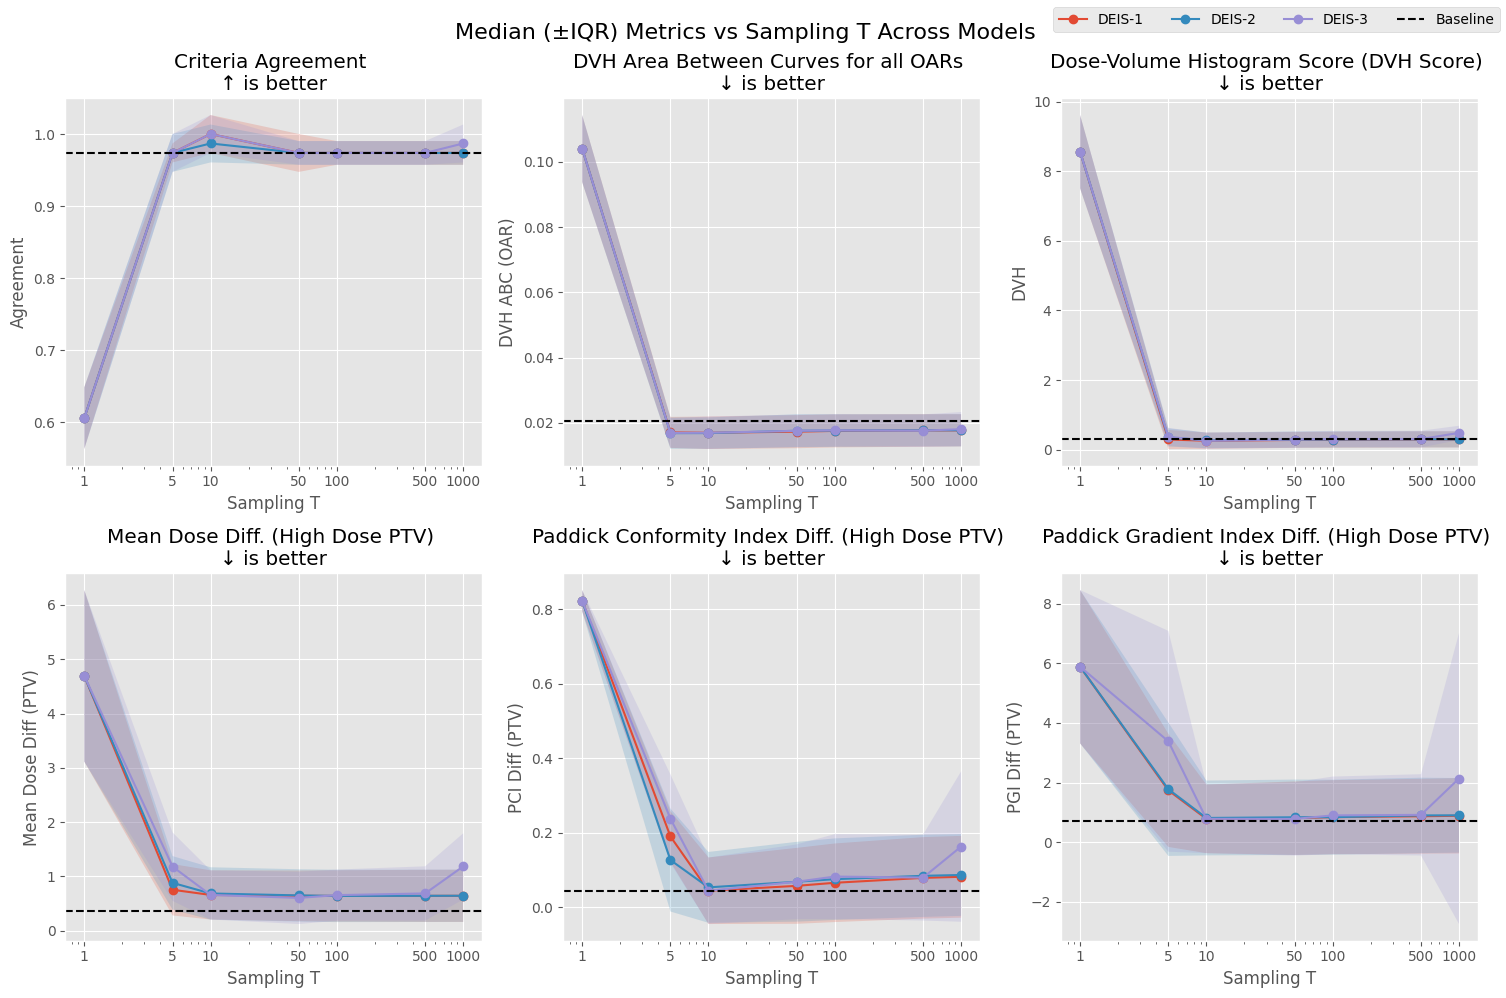

In [ ]:
_ = deis_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)

# Sampling Comparison

In [101]:
sampler_comparison = ModelComparison(
  [ddpm_1000, ddpm_500, ddpm_100, ddpm_50, ddpm_10, ddpm_5, ddpm_1,
   ddim_1000, ddim_500, ddim_100, ddim_50, ddim_10, ddim_5, ddim_1,
   deis_1_1000, deis_1_500, deis_1_100, deis_1_50, deis_1_10, deis_1_5, deis_1_1],
  ['DDPM T=1000', 'DDPM T=500', 'DDPM T=100', 'DDPM T=50', 'DDPM T=10', 'DDPM T=5', 'DDPM T=1',
   'DDIM T=1000', 'DDIM T=500', 'DDIM T=100', 'DDIM T=50', 'DDIM T=10', 'DDIM T=5', 'DDIM T=1',
   'DEIS-1 T=1000', 'DEIS-1 T=500', 'DEIS-1 T=100', 'DEIS-1 T=50', 'DEIS-1 T=10', 'DEIS-1 T=5', 'DEIS-1 T=1'],
  ['DDPM'] * 7 + ['DDIM'] * 7 + ['DEIS-1'] *7
)

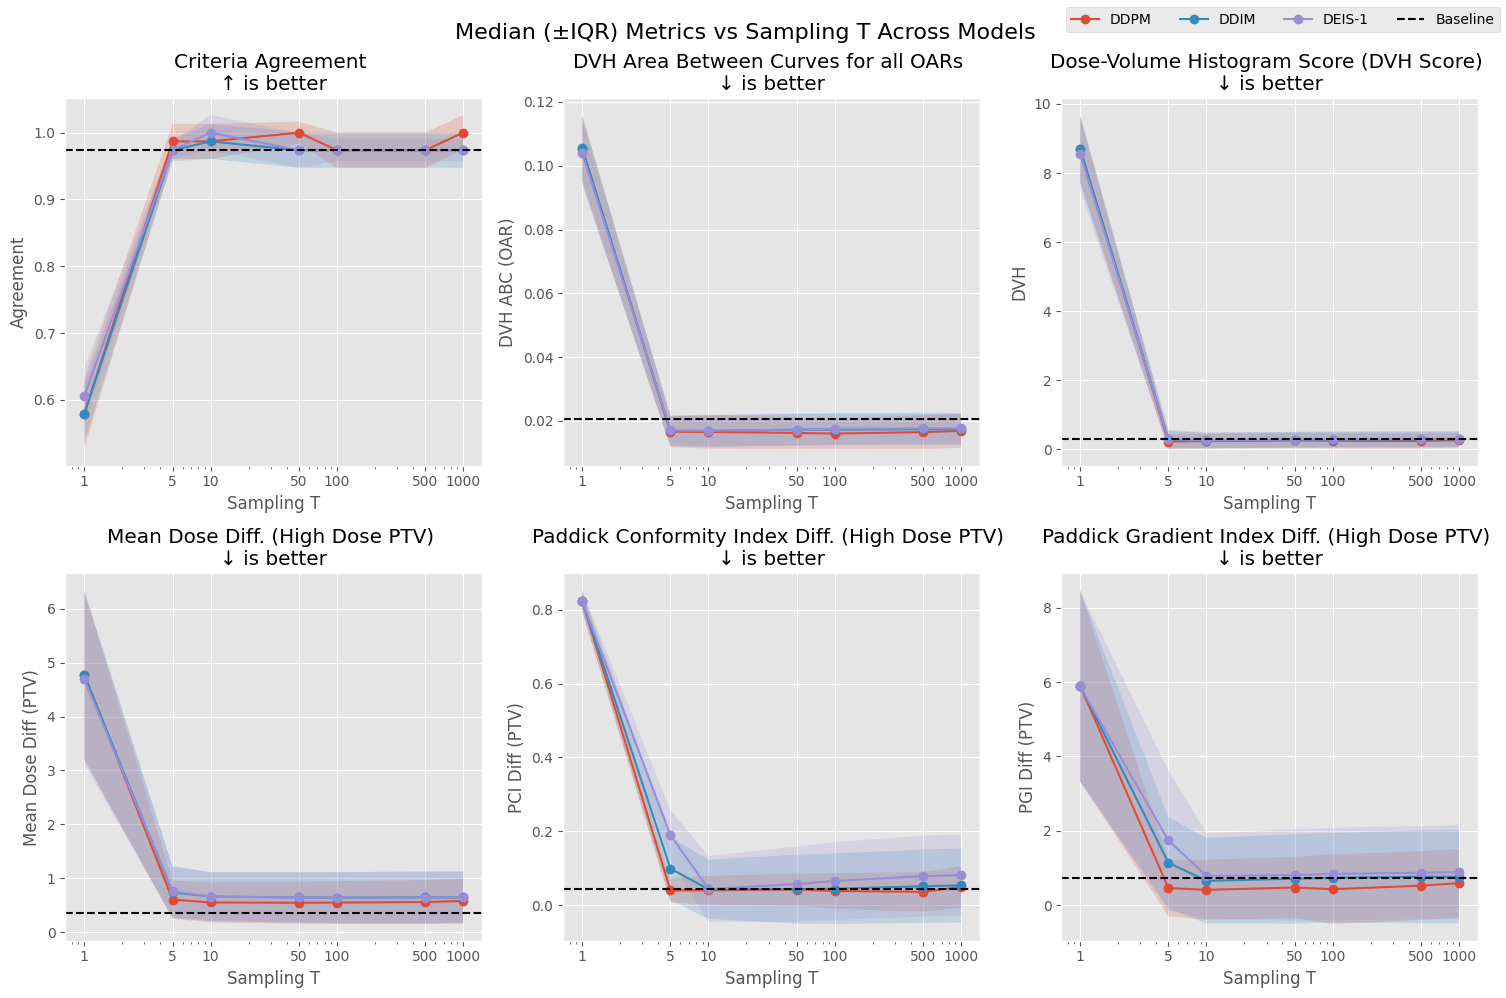

In [102]:
_ = sampler_comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)

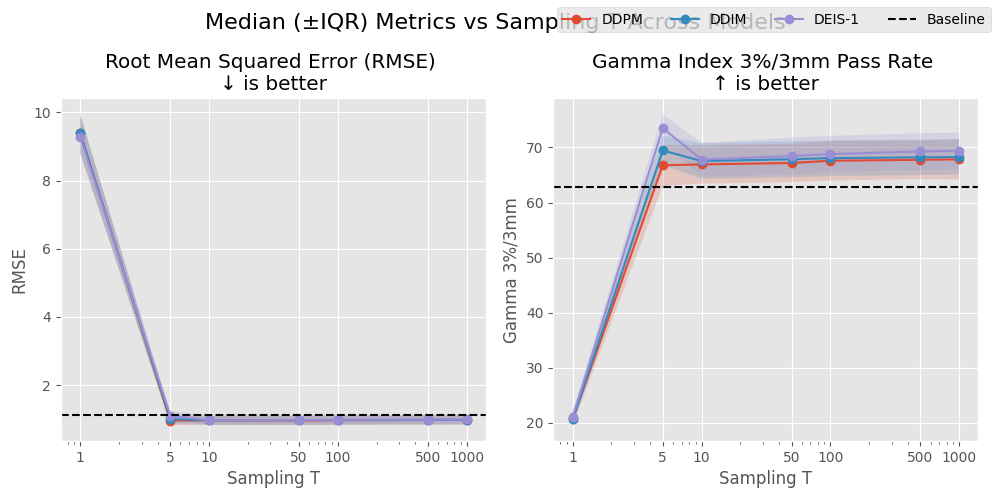

In [104]:
_ = sampler_comparison.plot_quality_over_T(['vol_rmse', 'vol_gamma_3_3/pass_rate'], agg='median', baseline=unet_baseline)